In [1]:
import xarray as xr
import numpy as np
import scipy.sparse as sps
import glob
from netCDF4 import default_fillvals
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import matplotlib as mpl

In [2]:
import dask
from dask.distributed import wait
dask.__version__

'2025.7.0'

In [3]:
# Close out Dask Cluster and release workers:
#cluster.close()
#client.close()

In [4]:
# TODO: optimize dask resources

def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=1,
        memory='40GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=40GB',
        project='NCGD0011',
        walltime='04:00:00',
        interface='ext',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

cluster, client = get_ClusterClient()
cluster.scale(36) 

/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/dask_jobqueue/core.py:266: FutureWarning: job_extra has been renamed to job_extra_directives. You are still using it (even if only set to []; please also check config files). If you did not set job_extra_directives yet, job_extra will be respected for now, but it will be removed in a future release. If you already set job_extra_directives, job_extra is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.12/site-packages/dask_jobqueue/pbs.py:82: FutureWarning: project has been renamed to account as this kwarg was used wit -A option. You are still using it (please also check config files). If you did not set account yet, project will be respected for now, but it will be removed in a future release. If you already set account, project is ignored and you can remove it.
  warnings.warn(warn, FutureWarning)
/glade/u/apps/opt/conda/envs/npl-2025b/lib/python3.1

In [5]:
cluster

Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/fredc/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.204:44049,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/fredc/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [6]:
fdir = '/glade/campaign/collections/rda/data/d651009/'
outdir = '/glade/derecho/scratch/fredc/RDA/'
case = 'b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.46-2006-2100.010'

In [7]:
fpath = '{}/{}/ocn/proc/tseries/month_1/{}.pop.h.SSH.200601-201512.nc'.format(fdir,case,case)
flst = sorted(glob.glob(fpath))

ds = xr.open_mfdataset(flst,
                       parallel=True, # use dask to read in parallel
                       combine="nested",  # combine files in order provided
                       concat_dim="time",  # concatentate files along time dimension
                       data_vars="minimal",  # only concatentate data variables with "time" dimension
                       coords="minimal",  # same as above for coordinate variables
                       compat="override",
                       #preprocess=preprocess, # run this function on each dataset first before combining
                       chunks={ "time":1,}, # choose simple
                       )

In [8]:
ds.SSH

<xarray.DataArray 'SSH' (time: 120, nlat: 2400, nlon: 3600)> Size: 4GB
dask.array<open_dataset-SSH, shape=(120, 2400, 3600), dtype=float32, chunksize=(1, 800, 1200), chunktype=numpy.ndarray>
Coordinates:
    ULONG    (nlat, nlon) float64 69MB dask.array<chunksize=(480, 720), meta=np.ndarray>
    ULAT     (nlat, nlon) float64 69MB dask.array<chunksize=(480, 720), meta=np.ndarray>
    TLONG    (nlat, nlon) float64 69MB dask.array<chunksize=(480, 720), meta=np.ndarray>
    TLAT     (nlat, nlon) float64 69MB dask.array<chunksize=(480, 720), meta=np.ndarray>
  * time     (time) object 960B 2006-02-01 00:00:00 ... 2016-01-01 00:00:00
Dimensions without coordinates: nlat, nlon
Attributes:
    long_name:     Sea Surface Height
    units:         centimeter
    grid_loc:      2110
    cell_methods:  time: mean

In [9]:
wgtfile = '/glade/work/fredc/Regrid_Maps/POP_tx0.1v2_to_latlon_1x1_0E_bilinear_20251113.nc'
dsw = xr.open_dataset(wgtfile)

In [10]:
def remap_pop(ds, dsw, varlst):
    # remap var from varlst in Dataset ds using regridding weights in Dataset dsw.
    dso = xr.full_like(ds.drop_dims('nlat'), np.nan)
    srclon = dsw.xc_a.values.reshape([dsw.src_grid_dims[1].values, dsw.src_grid_dims[0].values])
    srclat = dsw.yc_a.values.reshape([dsw.src_grid_dims[1].values, dsw.src_grid_dims[0].values])
    dstlon = dsw.xc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])[0]
    dstlat = dsw.yc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])[:,0]
    weights = sps.coo_matrix((dsw.S, (dsw.row-1, dsw.col-1)), shape=[dsw.sizes['n_b'], dsw.sizes['n_a']])
    for varname in varlst:
        shape_in = ds[varname].shape
        shape_out = dsw.dst_grid_dims.values[1],dsw.dst_grid_dims.values[0]
        srcmask = np.isnan(ds[varname].isel(time=0))
        srcvar_flat = ds.fillna(0)[varname].values.reshape(-1, shape_in[-2]*shape_in[-1])
        srcmask_flat = np.invert(srcmask).values.reshape(shape_in[-2]*shape_in[-1])
        remapped_flat = weights.dot(srcvar_flat.T).T
        remapped_msak_flat = weights.dot(srcmask_flat.T).T
        remapped = remapped_flat.reshape([*shape_in[0:-2], shape_out[0], shape_out[1]])
        remapped_mask = remapped_msak_flat.reshape([shape_out[0], shape_out[1]])
        remapped_mask[np.where(remapped_mask==0)] = 1 # avoid division by zero
        remapped = remapped / remapped_mask[None,:,:] # correct for land/sea mask
        remapped[np.where(remapped==0)] = default_fillvals['f8'] # spval
        dimlst = list(ds[varname].dims[0:-2])
        dims={}
        coords={}
        for it in dimlst:
            dims[it] = dso.dims[it]
            coords[it] = dso.coords[it]
        dims['lat'] = int(dsw.dst_grid_dims[1])
        dims['lon'] = int(dsw.dst_grid_dims[0])
        coords['lat'] = (['lat'], dstlat)
        coords['lon'] = (['lon'], dstlon)
        remapped = xr.DataArray(remapped, coords=coords, dims=dims, attrs=ds[varname].attrs)
        remapped['lat'].attrs = {'units':'degrees_north'}                                                       
        remapped['lon'].attrs = {'units':'degrees_east'}                                                        
        dso = xr.merge([dso, remapped.to_dataset(name=varname)])                                                
    return dso

In [11]:
%%time
dso = remap_pop(ds,dsw, ['SSH'])

CPU times: user 4.45 s, sys: 3.16 s, total: 7.61 s
Wall time: 15.6 s


/glade/derecho/scratch/fredc/tmp/ipykernel_28714/3220477464.py:26: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  dims[it] = dso.dims[it]


In [12]:
dso

<xarray.Dataset> Size: 63MB
Dimensions:             (z_t: 62, z_w: 62, time: 120, d2: 2, z_t_150m: 15,
                         z_w_top: 62, z_w_bot: 62, lat: 181, lon: 361)
Coordinates:
  * z_t                 (z_t) float32 248B 500.0 1.5e+03 ... 5.625e+05 5.875e+05
  * z_t_150m            (z_t_150m) float32 60B 500.0 1.5e+03 ... 1.45e+04
  * z_w                 (z_w) float32 248B 0.0 1e+03 2e+03 ... 5.5e+05 5.75e+05
  * z_w_top             (z_w_top) float32 248B 0.0 1e+03 ... 5.5e+05 5.75e+05
  * z_w_bot             (z_w_bot) float32 248B 1e+03 2e+03 ... 5.75e+05 6e+05
  * time                (time) object 960B 2006-02-01 00:00:00 ... 2016-01-01...
  * lat                 (lat) float64 1kB -90.0 -89.0 -88.0 ... 88.0 89.0 90.0
  * lon                 (lon) float64 3kB 0.0 1.0 2.0 3.0 ... 358.0 359.0 360.0
Dimensions without coordinates: d2
Data variables: (12/34)
    dz                  (z_t) float32 248B dask.array<chunksize=(62,), meta=np.ndarray>
    dzw                 (z_w) float32 248B dask.array<chunksize=(62,), meta=np.ndarray>
    days_in_norm_year   timedelta64[ns] 8B NaT
    grav                float64 8B nan
    omega               float64 8B nan
    radius              float64 8B nan
    ...                  ...
    salinity_factor     float64 8B nan
    sflux_factor        float64 8B nan
    nsurface_t          float64 8B nan
    nsurface_u          float64 8B nan
    time_bound          (time, d2) object 2kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    SSH                 (time, lat, lon) float64 63MB 9.969e+36 ... -59.45
Attributes:
    title:         b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.46-2006-2100.010
    history:       none
    Conventions:   CF-1.0; http://www.cgd.ucar.edu/cms/eaton/netcdf/CF-curren...
    contents:      Diagnostic and Prognostic Variables
    source:        CCSM POP2, the CCSM Ocean Component
    revision:      $Id: tavg.F90 56176 2013-12-20 18:35:46Z mlevy@ucar.edu $
    calendar:      All years have exactly  365 days.
    start_time:    This dataset was created on 2023-12-26 at 09:53:44.7
    cell_methods:  cell_methods = time: mean ==> the variable values are aver...
    nsteps_total:  19331
    tavg_sum:      2676600.0

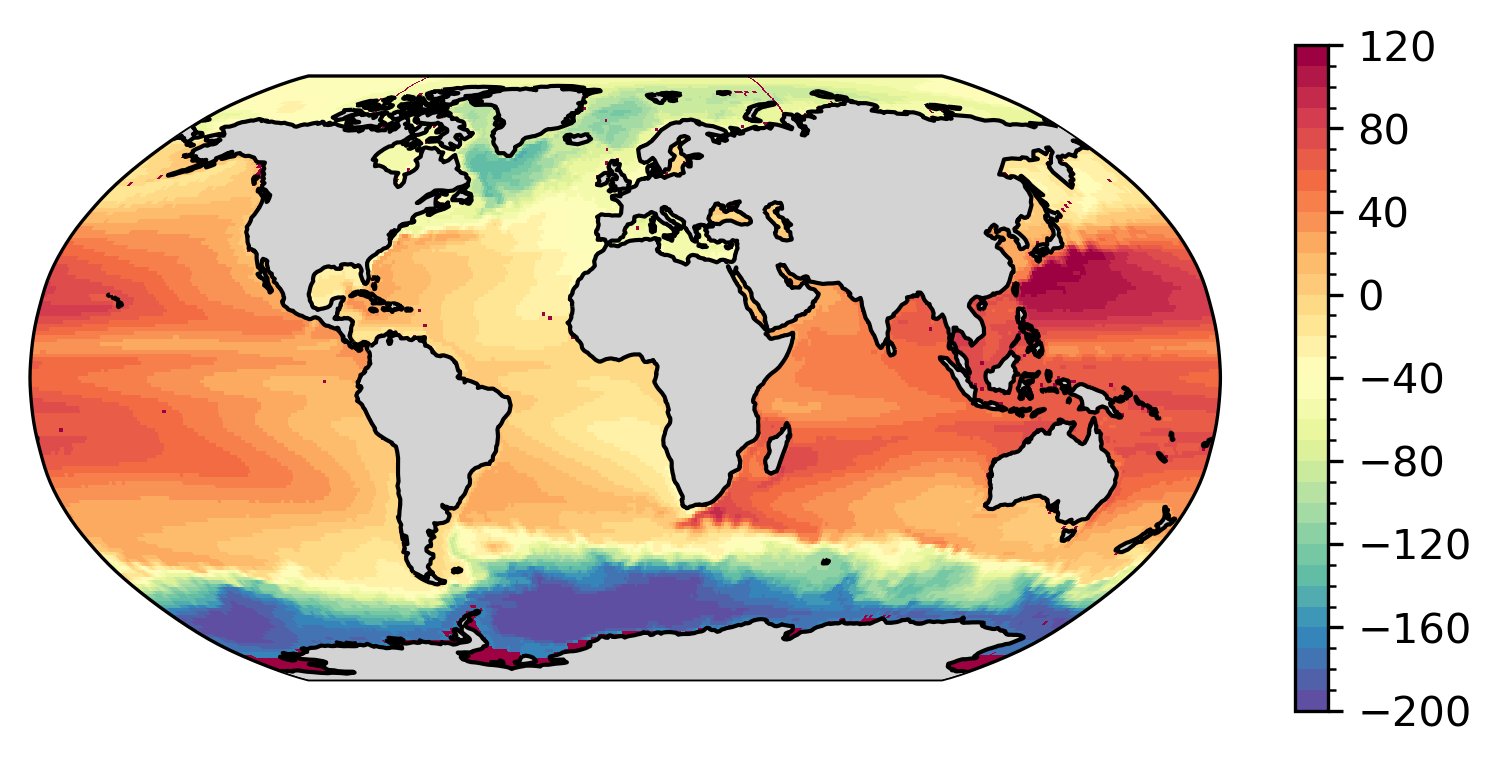

In [14]:
cmap = plt.cm.Spectral_r
clevs = np.arange(-200,121,10)
lon, lat = np.meshgrid(dso.lon.values, dso.lat.values)
plt.figure(dpi=300)
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
cf = ax.pcolormesh(lon, lat, dso.SSH.mean('time'), 
                   cmap=cmap,
                   norm=mpl.colors.BoundaryNorm(clevs, ncolors=cmap.N), 
                   transform=ccrs.PlateCarree()
                   )
ax.add_feature(cartopy.feature.LAND, fc='lightgray', zorder=10)
ax.coastlines(resolution='110m', zorder=20)  # looks better with resolution='10m'
ax.set_global()
plt.colorbar(cf, shrink=0.6)